# UC2 · Jalon 1 — Trois tâches avec des MLP
 **Groupe 13 · Master SDIA-2 · ENSET Mohammedia**  
 Agrigah Aya · AARAB Mustapha · Toubani Badr Eddine

 Prédire catégorie, prix en DH et achat. Isoler les modalités, comparer les six couples cible/perte de prix et étudier les descripteurs de sessions.

 **Données officielles :** les quatre fichiers NPZ du dossier `Use Cases.rar`,
 partitions imposées conservées. Fashion-MNIST fournit les images ; descriptions,
 prix, boutique B et sessions sont des données pédagogiques simulées. Nous
 n'affirmons pas entraîner un système de production sur de vraies ventes.

 Le projet Kaggle antérieur reste dans `annexes/historique_kaggle`. Il ne possède
 pas les prix/sessions ni les partitions imposées. Ses scores ne sont pas mêlés
 aux résultats de cette remise. Le groupe a utilisé une assistance IA pour le
 code, la rédaction et les contrôles ; les sorties chiffrées sont calculées.

## Exécution et fichiers à conserver
 1. Décompresser **toute** l'archive, garder `data_UC2/` et `src/` avec les notebooks.
 2. Suivre le README pour l'environnement Python 3.12, TensorFlow 2.20 / Keras 3.11.3.
 3. VS Code : extensions Python/Jupyter, choisir `.venv-uc2` comme noyau. Colab :
    GPU facultatif, placer le dossier complet dans Drive puis ouvrir ce notebook.
 4. Exécuter dans l'ordre. Les modèles livrés sont réutilisés lorsqu'ils sont compatibles.
    Pour une nouvelle exécution indépendante, renseigner `RUN_LABEL` ci-dessous.
 5. Sauvegarder le notebook avec sorties. Les modèles, courbes, journal et décisions
    s'enregistrent dans `artifacts/jalonN/` (ou `reruns/RUN_LABEL/jalonN/`).

 Tous les réglages précèdent l'ouverture du test. La session finale est figée par
 empreintes des poids et de la configuration. Une relance lit les résultats
 finalisés. Ne pas modifier un modèle/seuil après accès au test pour améliorer
 artificiellement le score. Les comparateurs fixés sont évalués dans cette même
 session finale. Le temps mesuré dépend du matériel et exclut l'installation.

In [1]:
import os,sys,subprocess
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL","2")
assert (3,10)<=sys.version_info[:2]<=(3,13), "Utiliser Python 3.12."
# Configuration facultative avant exécution, pas après le test.
PROJECT_DIR = None  # Colab : "/content/drive/MyDrive/GroupeXX_UC2"
RUN_LABEL = ""      # ex. "reproduction_cpu" pour un nouveau dossier de résultats
if PROJECT_DIR:
    ROOT=Path(PROJECT_DIR).expanduser().resolve()
else:
    candidates=[Path.cwd(),Path.cwd().parent]
    ROOT=next((p for p in candidates if (p/"data_UC2/uc2_catalogueA.npz").exists()),None)
    if ROOT is None:raise FileNotFoundError("Ouvrir le dossier complet de l'archive ou définir PROJECT_DIR.")
sys.path.insert(0,str(ROOT/"src"))
from uc2_utils import *
from tensorflow.keras import layers
CFG={'epochs': 20, 'batch': 128, 'patience': 4, 'classification_selection': 'macro F1 val', 'price_selection': 'MAPE val', 'session_selection': 'AUC val', 'dropout': 0.3, 'l2': 0.0001}
OUT,ENV,DATA_SHA=initialise(ROOT,1,CFG,RUN_LABEL)
display(pd.DataFrame([ENV]).T.rename(columns={0:"Valeur"}))
print("Dossier :",ROOT,"| résultats :",OUT)
print("GPU :",ENV["devices"] or "CPU (4 threads)")

KeyboardInterrupt: 

## 1. Cahier des charges et protocole
 | Expérience demandée | Réalisation |
 |---|---|
 | Image seule, texte seul, fusion | Trois MLP + contrôles sans régularisation et L2 |
 | Prix brut/log, MSE/MAE/Huber | Six entraînements, prix médian de la catégorie prédite |
 | Achat et derniers événements | Logistique de comptages, MLP comptages et MLP riche |
 | Dropout/L2/arrêt anticipé | Budget 20 époques, patience 4, choix sur validation |
 | Théorie | 169 mots, paramètres MLP, erreurs à 400 DH |

 Sorties : softmax 10 + entropie croisée pour catégorie, linéaire pour prix ou
 log-prix, sigmoid + entropie croisée binaire pour achat. Métriques de sélection :
 F1 macro, MAPE en DH et AUC. La normalisation des descripteurs et le vocabulaire
 utilisent uniquement l'entraînement. Nous conservons les descriptions vides :
 elles représentent un manque d'information, pas une ligne à supprimer.

169 mots : 169 | entrées fusion : 953
Images val exactement présentes dans train : 0 (aucune partition changée)


,split,rows,empty_descriptions,median_price_dh,min_price_dh,max_price_dh
0,train,20000,1043,270.0,30.0,2735.0
1,val,4000,225,265.0,35.0,2585.0


,train,val
T-shirt/top,1935,393
Pantalon,2025,404
Pull,1982,406
Robe,2011,416
Manteau,1967,417
Sandale,2010,405
Chemise,2068,405
Basket,2003,400
Sac,1971,352
Bottine,2028,402


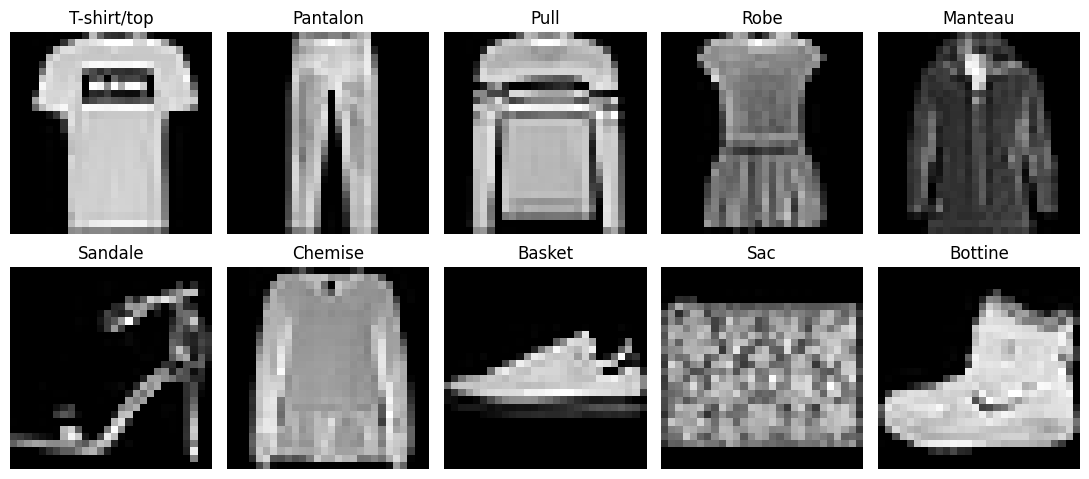

In [ ]:
A=load_catalogue(ROOT,'A');S=load_sessions(ROOT)
display(catalogue_audit(A));assert len(A['X_train'])==20000 and len(A['X_val'])==4000
BOW=fit_bow(A);write_json(OUT/'vocabulary.json',BOW.vocabulary_)
INPUT={s:{'image':flat_input(A,s),'mots':bow_input(BOW,A,s)} for s in ['train','val']}
labels={s:A['categorie_'+s] for s in ['train','val']}
print('169 mots :',len(BOW.vocabulary_),'| entrées fusion :',784+len(BOW.vocabulary_))
dist=pd.DataFrame({s:np.bincount(labels[s],minlength=10) for s in ['train','val']},index=CLASSES)
display(dist);dist.to_csv(OUT/'class_distribution.csv')
fig,axes=plt.subplots(2,5,figsize=(11,5))
for k,ax in enumerate(axes.flat):
    i=np.flatnonzero(labels['train']==k)[0];ax.imshow(A['X_train'][i],cmap='gray');ax.set_title(CLASSES[k]);ax.axis('off')
fig.tight_layout();fig.savefig(OUT/'training_examples.png',dpi=150);plt.show();plt.close(fig)
# Les doublons sont rapportés, sans modifier les partitions imposées.
htrain={hashlib.sha256(x.tobytes()).hexdigest() for x in A['X_train']}
overlap=sum(hashlib.sha256(x.tobytes()).hexdigest() in htrain for x in A['X_val'])
write_json(OUT/'audit.json',{'fixed_partitions_preserved':True,'exact_train_val_image_overlap':overlap,'empty_titles_retained':True})
print('Images val exactement présentes dans train :',overlap,'(aucune partition changée)')

## 2. Vérifications théoriques
 Le MLP de référence concatène 784 pixels et 169 mots, puis Dense256, Dropout et
 Dense10. Les paramètres sont `(953+1)×256 + (256+1)×10 = 246 794`.

 Pour 400 DH : les prédictions 300 et 500 ont toutes deux une erreur quadratique
 brute de 10 000 DH². En log : `(ln(300)-ln(400))² ≈ 0,08276`, contre
 `(ln(500)-ln(400))² ≈ 0,04979`. Le log donne plus d'importance aux écarts
 multiplicatifs qu'aux grands montants absolus ; il ne garantit pas le meilleur
 MAPE. Les deux prédictions ont MAPE 25%, ce qui distingue métrique et perte.

Model: "functional"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 784)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mots (InputLayer)   │ (None, 169)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 953)       │          0 │ image[0][0],      │
│ (Concatenate)       │                   │            │ mots[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden (Dense)      │ (None, 256)       │    244,224 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │

{'mlp_parameters': 246794,
 'raw_squared_errors': [10000, 10000],
 'log_squared_errors': [np.float64(0.08276097481015166),
  np.float64(0.04979304449311734)]}

,model,macro_f1,accuracy,parameters,trainable_parameters,seconds,best_epoch,modality,dropout,l2
0,MLP_image,0.878165,0.87750,203530,203530,11.113238,12,image,0.3,0.0000
1,MLP_text,0.756499,0.74800,46090,46090,4.982956,7,text,0.3,0.0000
2,MLP_reference,0.944427,0.94350,246794,246794,12.749259,14,both,0.3,0.0000
3,MLP_no_regularization,0.942088,0.94125,246794,246794,7.424989,9,both,0.0,0.0000
4,MLP_L2_dropout,0.943466,0.94275,246794,246794,11.525232,14,both,0.3,0.0001


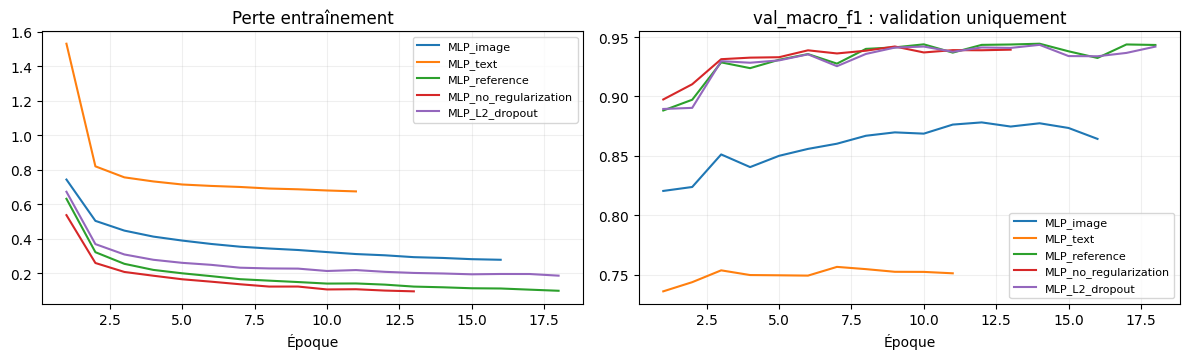

In [ ]:
def category_mlp(modality='both',dropout=.3,l2=0.):
    if modality=='both':
        image=keras.Input((784,),name='image');mots=keras.Input((169,),name='mots')
        inputs={'image':image,'mots':mots};x=layers.Concatenate()([image,mots])
    else:
        inputs=keras.Input((784 if modality=='image' else 169,),name=modality);x=inputs
    x=layers.Dense(256,activation='relu',kernel_regularizer=keras.regularizers.l2(l2),name='hidden')(x)
    x=layers.Dropout(dropout)(x);out=layers.Dense(10,activation='softmax',name='categorie')(x)
    model=keras.Model(inputs,out);model.compile(keras.optimizers.Adam(1e-3),'sparse_categorical_crossentropy',metrics=['accuracy'])
    return model
theory=category_mlp();assert theory.count_params()==246794;theory.summary()
theory_results={'mlp_parameters':theory.count_params(),'raw_squared_errors':[10000,10000],
    'log_squared_errors':[(np.log(300)-np.log(400))**2,(np.log(500)-np.log(400))**2]}
write_json(OUT/'theory_checks.json',theory_results);display(theory_results)
CAT_SPECS={'MLP_image':('image',.3,0.),'MLP_text':('text',.3,0.),'MLP_reference':('both',.3,0.),
           'MLP_no_regularization':('both',0.,0.),'MLP_L2_dropout':('both',.3,1e-4)}
CAT_MODELS={};cat_rows=[];CAT_X={}
for name,(modality,drop,l2) in CAT_SPECS.items():
    x={s:INPUT[s] if modality=='both' else INPUT[s]['image' if modality=='image' else 'mots'] for s in ['train','val']}
    model,info=fit_model(OUT,name,lambda m=modality,d=drop,l=l2:category_mlp(m,d,l),x['train'],labels['train'],x['val'],labels['val'],
        epochs=CFG['epochs'],monitor='val_macro_f1',mode='max',evaluator=lambda p:{'val_macro_f1':classifier_metrics(labels['val'],p)['macro_f1']})
    CAT_MODELS[name]=model;CAT_X[name]=x
    cat_rows.append(validation_row(OUT,name,info,classifier_metrics(labels['val'],predict(model,x['val'])),modality=modality,dropout=drop,l2=l2))
CAT_VAL=write_table(OUT,'classification_validation',cat_rows)
SELECTED_CAT=CAT_VAL.sort_values(['macro_f1','parameters'],ascending=[False,True]).iloc[0].model
print('Catégorie retenue :',SELECTED_CAT)
learning_curves(OUT,list(CAT_SPECS),'val_macro_f1','classification_learning.png')

,MLP_image,MLP_text,MLP_reference
T-shirt/top,0.828571,0.732283,0.904943
Pantalon,0.977556,0.800550,0.990050
Pull,0.786967,0.719895,0.894063
Robe,0.896635,0.778626,0.962241
Manteau,0.805167,0.714286,0.914141
Sandale,0.961298,0.806412,0.978882
Chemise,0.675497,0.577169,0.864799
Basket,0.935687,0.819892,0.970297
Sac,0.964337,0.826866,0.988571
Bottine,0.949939,0.789014,0.976280


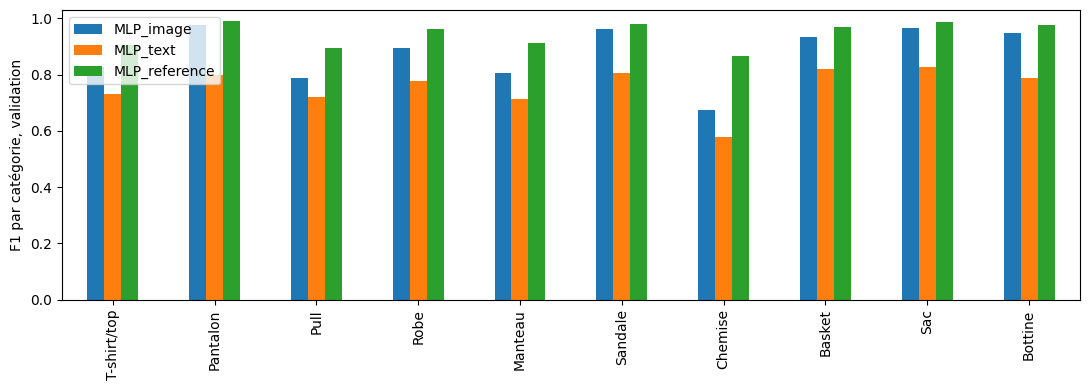

In [ ]:
modality_f1={n:per_class(labels['val'],predict(CAT_MODELS[n],CAT_X[n]['val'])).f1.values for n in ['MLP_image','MLP_text','MLP_reference']}
MODALITY=pd.DataFrame(modality_f1,index=CLASSES);display(MODALITY);MODALITY.to_csv(OUT/'modality_per_class_validation.csv')
fig,ax=plt.subplots(figsize=(11,4));MODALITY.plot.bar(ax=ax);ax.set_ylabel('F1 par catégorie, validation');ax.set_ylim(0,1.03)
fig.tight_layout();fig.savefig(OUT/'modality_comparison.png',dpi=150);plt.show();plt.close(fig)

## 3. Six essais de prix et référence médiane
 Les cibles brutes restent en DH. Le biais initial est la moyenne de la cible
 **d'entraînement**. Pour le log-prix, exponentier la sortie linéaire. Huber :
 delta=50 DH sur brut, 0,5 sur log. Ces unités différentes sont explicites.
 La sortie linéaire ne garantit pas un prix brut positif : on compte les sorties
 non positives et on applique une borne minimale de 1 DH, préannoncée.
 L'exponentielle est bornée par un intervalle large obtenu sur train pour éviter
 un débordement numérique. Arrêt anticipé sur MAPE validation en DH pour tous.

 La médiane utilise la catégorie **prédite**, jamais l'étiquette de validation/test
 comme entrée. Une médiane avec vraie catégorie est seulement un diagnostic val.

Prix retenu : price_log_huber


,model,mape,mae_dh,rmse_dh,nonpositive_predictions,parameters,trainable_parameters,seconds,best_epoch,target,loss,activation
0,price_raw_mse,0.533504,141.245698,215.457359,0,122241,122241,6.908393,8,raw,mse,linear
1,price_raw_mae,0.422183,128.536171,213.936464,0,122241,122241,11.169892,17,raw,mae,linear
2,price_raw_huber,0.429620,128.099610,211.665064,0,122241,122241,11.302206,17,raw,huber,linear
3,price_log_mse,0.323875,124.059449,212.677623,0,122241,122241,5.550825,6,log,mse,linear
4,price_log_mae,0.340722,118.976987,202.179470,0,122241,122241,3.831323,3,log,mae,linear
5,price_log_huber,0.322625,122.087227,209.661906,0,122241,122241,5.541161,6,log,huber,linear


,model,mape,mae_dh,rmse_dh,nonpositive_predictions
0,median_predicted_category,0.441491,145.3300,236.24291,0
1,median_true_category_diagnostic_val_only,0.419679,140.9625,229.96179,0


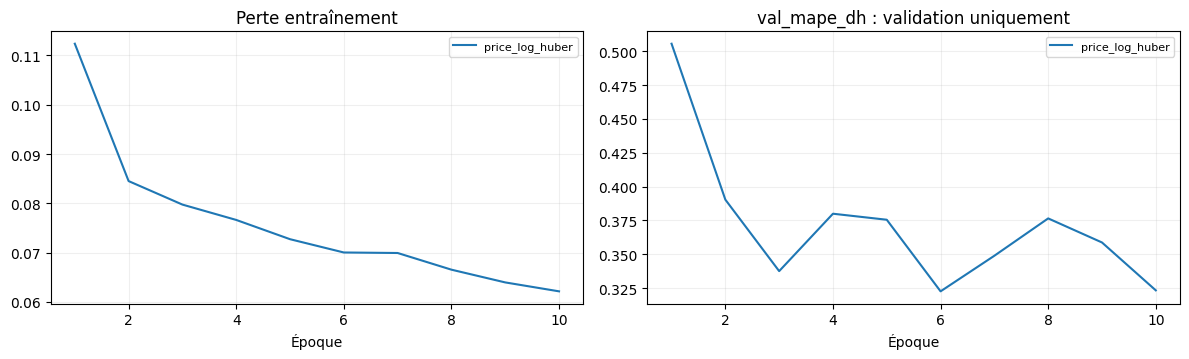

In [ ]:
def decode_price(p,target):
    p=np.asarray(p).reshape(-1)
    return np.exp(np.clip(p,np.log(1.),np.log(float(A['prix_train'].max())*10))) if target=='log' else np.maximum(p,1.)
def price_mlp(target,loss):
    image=keras.Input((784,),name='image');mots=keras.Input((169,),name='mots')
    x=layers.Concatenate()([image,mots]);x=layers.Dense(128,activation='relu')(x)
    y=np.log(A['prix_train']) if target=='log' else A['prix_train']
    output=layers.Dense(1,activation='linear',bias_initializer=keras.initializers.Constant(float(y.mean())))(x)
    m=keras.Model({'image':image,'mots':mots},output)
    function=keras.losses.Huber(delta=.5 if target=='log' else 50.) if loss=='huber' else loss
    m.compile(keras.optimizers.Adam(1e-3),function);return m
PRICE_MODELS={};price_rows=[]
for target in ['raw','log']:
    yt=np.log(A['prix_train']) if target=='log' else A['prix_train']
    yv=np.log(A['prix_val']) if target=='log' else A['prix_val']
    for loss in ['mse','mae','huber']:
        name=f'price_{target}_{loss}'
        model,info=fit_model(OUT,name,lambda t=target,l=loss:price_mlp(t,l),INPUT['train'],yt,INPUT['val'],yv,
            epochs=CFG['epochs'],monitor='val_mape_dh',mode='min',
            evaluator=lambda p,t=target:{'val_mape_dh':price_metrics(A['prix_val'],decode_price(p,t))['mape']})
        PRICE_MODELS[name]=model
        price_rows.append(validation_row(OUT,name,info,price_metrics(A['prix_val'],decode_price(predict(model,INPUT['val']),target)),target=target,loss=loss,activation='linear'))
PRICE_VAL=write_table(OUT,'price_validation',price_rows)
SELECTED_PRICE=PRICE_VAL.sort_values(['mape','parameters']).iloc[0].model
PRICE_TARGET=PRICE_VAL.set_index('model').loc[SELECTED_PRICE,'target']
MEDIANS=np.array([np.median(A['prix_train'][labels['train']==k]) for k in range(10)])
write_json(OUT/'category_price_medians.json',MEDIANS)
ref_cat=predict(CAT_MODELS['MLP_reference'],INPUT['val']).argmax(1)
median_row={'model':'median_predicted_category',**price_metrics(A['prix_val'],MEDIANS[ref_cat])}
oracle_row={'model':'median_true_category_diagnostic_val_only',**price_metrics(A['prix_val'],MEDIANS[labels['val']])}
display(pd.DataFrame([median_row,oracle_row]));write_json(OUT/'price_baseline_validation.json',[median_row,oracle_row])
journal(OUT,'median_predicted_category','validation','measured',**{k:v for k,v in median_row.items() if k!='model'})
print('Prix retenu :',SELECTED_PRICE);learning_curves(OUT,[SELECTED_PRICE],'val_mape_dh','price_learning.png')

## 4. Achat : comptages et derniers événements
 La logistique de référence reçoit cinq comptages de types, sans ordre. Les deux
 MLP utilisent soit ces comptages, soit des statistiques de durée/prix/catégorie
 et cinq derniers types en one-hot avec présence explicite. Les catégories et
 types sont des entrées, **achat n'en est jamais une**. StandardScaler sur train.
 La référence garde C=1 préannoncé. Les types 1–5 sont les codes fournis ; aucun
 sens supplémentaire n'est inventé pour les codes sans dictionnaire fourni.

,model,auc,average_precision,precision_top10,targeted_rows,positive_rate,parameters,seconds,features,trainable_parameters,best_epoch
0,logistic_counts,0.778188,0.529004,0.5775,400,0.27525,6,0.000000,5,NaN,NaN
1,session_counts_mlp,0.787374,0.538477,0.6150,400,0.27525,2497,3.012907,5,2497.0,6.0
2,session_rich_mlp,0.831124,0.663729,0.7800,400,0.27525,5953,6.511963,59,5953.0,19.0


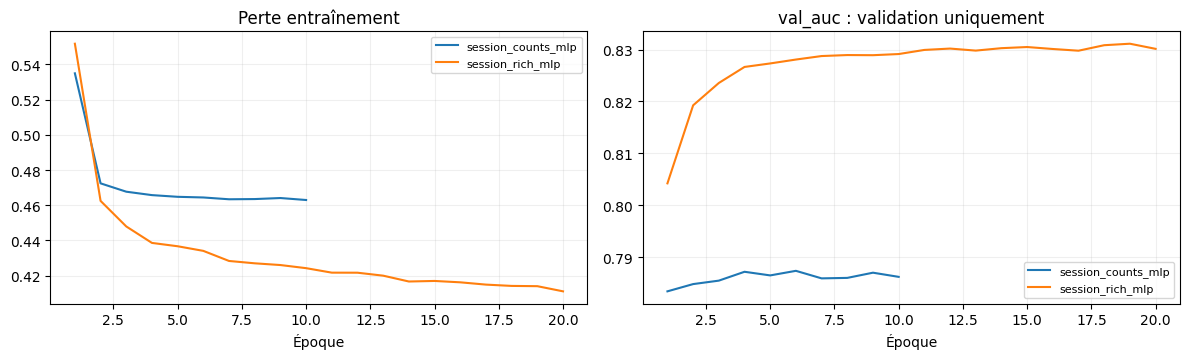

In [ ]:
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
counts={s:session_features(S,s) for s in ['train','val']}
rich={s:session_features(S,s,rich=True) for s in ['train','val']}
SY={s:S['achat_'+s] for s in ['train','val']}
LR=make_pipeline(StandardScaler(),LogisticRegression(C=1.,max_iter=1000,random_state=42))
LR.fit(counts['train'],SY['train']);joblib.dump(LR,OUT/'logistic_reference.joblib')
lr_val=session_metrics(SY['val'],LR.predict_proba(counts['val'])[:,1])
journal(OUT,'logistic_counts','validation','measured',**lr_val)
def session_mlp(n):
    inp=keras.Input((n,));x=layers.Dense(64,activation='relu',kernel_regularizer=keras.regularizers.l2(1e-4))(inp)
    x=layers.Dropout(.3)(x);x=layers.Dense(32,activation='relu')(x);out=layers.Dense(1,activation='sigmoid')(x)
    m=keras.Model(inp,out);m.compile(keras.optimizers.Adam(1e-3),'binary_crossentropy');return m
SESSION_MODELS={};SESSION_SCALERS={};SESSION_X={};session_rows=[]
for name,raw in [('session_counts_mlp',counts),('session_rich_mlp',rich)]:
    scaler=StandardScaler().fit(raw['train']);x={s:scaler.transform(raw[s]).astype('float32') for s in ['train','val']}
    model,info=fit_model(OUT,name,lambda n=x['train'].shape[1]:session_mlp(n),x['train'],SY['train'],x['val'],SY['val'],
        epochs=CFG['epochs'],monitor='val_auc',mode='max',evaluator=lambda p:{'val_auc':session_metrics(SY['val'],p)['auc'],'val_p10':session_metrics(SY['val'],p)['precision_top10']})
    SESSION_MODELS[name]=model;SESSION_SCALERS[name]=scaler;SESSION_X[name]=x
    joblib.dump(scaler,OUT/(name+'_scaler.joblib'))
    session_rows.append(validation_row(OUT,name,info,session_metrics(SY['val'],predict(model,x['val'])),features=x['train'].shape[1]))
SESSION_VAL=write_table(OUT,'session_validation',[{'model':'logistic_counts',**lr_val,'parameters':6,'seconds':0.,'features':5},*session_rows])
SELECTED_SESSION=SESSION_VAL[SESSION_VAL.model!='logistic_counts'].sort_values(['auc','precision_top10'],ascending=False).iloc[0].model
learning_curves(OUT,list(SESSION_MODELS),'val_auc','session_learning.png')

## 5. Session finale figée
 Les modèles retenus par validation et les comparateurs fixes sont maintenant
 gelés. Cette cellule charge **pour la première fois** les tableaux de test.
 Les variantes non retenues ont uniquement des scores validation.

In [ ]:
cat_modality=CAT_SPECS[SELECTED_CAT][0]
selection={'category':SELECTED_CAT,'price':SELECTED_PRICE,'session':SELECTED_SESSION,
           'fixed_comparators':['MLP_reference for predicted category medians','logistic_counts'],
           'models':sorted(set([SELECTED_CAT,SELECTED_PRICE,SELECTED_SESSION,'MLP_reference'])),
           'logistic_sha':sha_file(OUT/'logistic_reference.joblib')}
def evaluate_final():
    at=load_catalogue(ROOT,'A',('test',));st=load_sessions(ROOT,('test',))
    inp={'image':flat_input(at,'test'),'mots':bow_input(BOW,at,'test')}
    x=inp if cat_modality=='both' else inp['image' if cat_modality=='image' else 'mots']
    pc=predict(CAT_MODELS[SELECTED_CAT],x)
    pp=decode_price(predict(PRICE_MODELS[SELECTED_PRICE],inp),PRICE_TARGET)
    median=MEDIANS[predict(CAT_MODELS['MLP_reference'],inp).argmax(1)]
    raw=session_features(st,'test',rich=SELECTED_SESSION=='session_rich_mlp')
    xs=SESSION_SCALERS[SELECTED_SESSION].transform(raw).astype('float32')
    ps=predict(SESSION_MODELS[SELECTED_SESSION],xs).ravel()
    plr=LR.predict_proba(session_features(st,'test'))[:,1]
    np.savez_compressed(OUT/'test_predictions.npz',category_probability=pc,price=pp,median_price=median,
        session_probability=ps,logistic_probability=plr,category_true=at['categorie_test'],price_true=at['prix_test'],purchase_true=st['achat_test'])
    return {'category':{'model':SELECTED_CAT,**classifier_metrics(at['categorie_test'],pc)},
        'price':{'model':SELECTED_PRICE,**price_metrics(at['prix_test'],pp)},
        'median_price_reference':price_metrics(at['prix_test'],median),
        'purchase':{'model':SELECTED_SESSION,**session_metrics(st['achat_test'],ps)},
        'logistic_reference':session_metrics(st['achat_test'],plr)}
TEST=test_once(OUT,selection,evaluate_final);display(pd.DataFrame(TEST).T)

,model,macro_f1,accuracy,mape,mae_dh,rmse_dh,nonpositive_predictions,auc,average_precision,precision_top10,targeted_rows,positive_rate
category,MLP_reference,0.931578,0.930833,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,price_log_huber,NaN,NaN,0.326191,120.732915,203.537138,0,NaN,NaN,NaN,NaN,NaN
median_price_reference,NaN,NaN,NaN,0.45758,146.169167,231.494555,0.0,NaN,NaN,NaN,NaN,NaN
purchase,session_rich_mlp,NaN,NaN,NaN,NaN,NaN,NaN,0.834399,0.651961,0.778333,600,0.2665
logistic_reference,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.781611,0.517853,0.595,600.0,0.2665


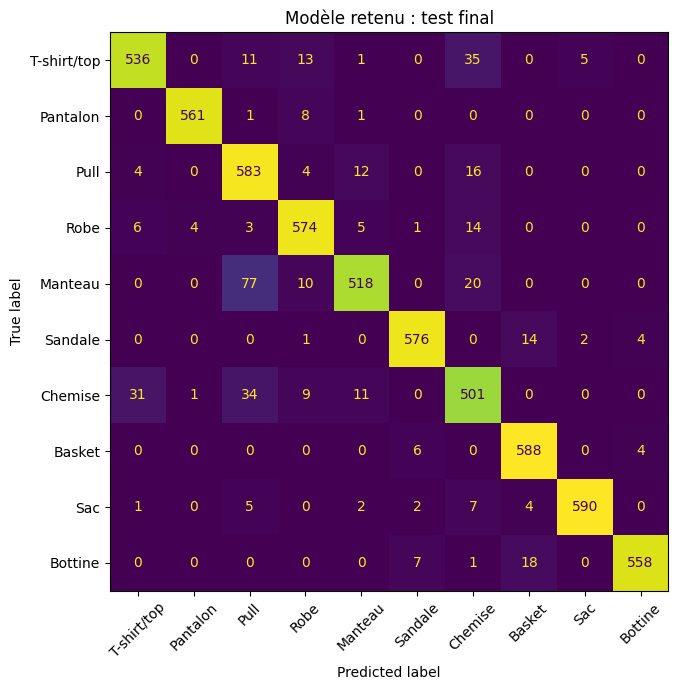

,category,f1,support
0,T-shirt/top,0.909245,601
1,Pantalon,0.986807,571
2,Pull,0.874719,619
3,Robe,0.936378,607
4,Manteau,0.881702,625
5,Sandale,0.968881,597
6,Chemise,0.848434,587
7,Basket,0.962357,598
8,Sac,0.976821,611
9,Bottine,0.970435,584


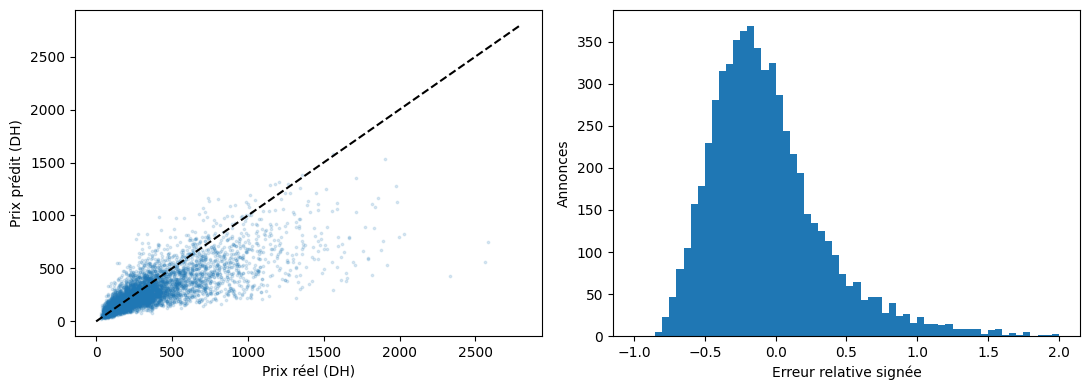

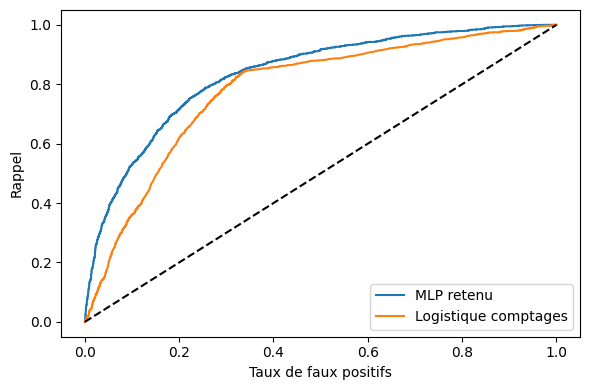

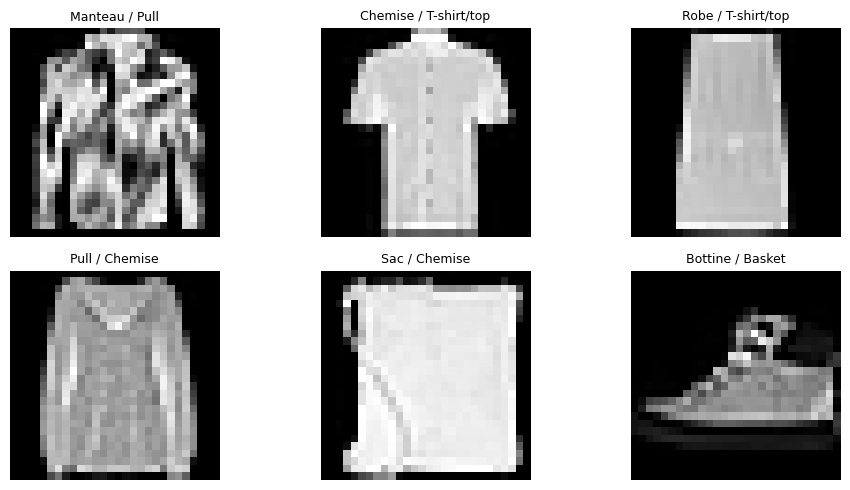

In [ ]:
z=np.load(OUT/'test_predictions.npz');show_confusion(z['category_true'],z['category_probability'],OUT)
pc=per_class(z['category_true'],z['category_probability']);display(pc);pc.to_csv(OUT/'test_per_class.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(z['price_true'],z['price'],s=3,alpha=.15);axes[0].plot([0,2800],[0,2800],'k--');axes[0].set(xlabel='Prix réel (DH)',ylabel='Prix prédit (DH)')
relative=(z['price']-z['price_true'])/z['price_true'];axes[1].hist(relative,bins=60,range=(-1,2));axes[1].set(xlabel='Erreur relative signée',ylabel='Annonces')
fig.tight_layout();fig.savefig(OUT/'price_test_analysis.png',dpi=150);plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(6,4))
for name,key in [('MLP retenu','session_probability'),('Logistique comptages','logistic_probability')]:
    fpr,tpr,_=roc_curve(z['purchase_true'],z[key]);ax.plot(fpr,tpr,label=name)
ax.plot([0,1],[0,1],'k--');ax.set(xlabel='Taux de faux positifs',ylabel='Rappel');ax.legend();fig.tight_layout();fig.savefig(OUT/'purchase_roc.png',dpi=150);plt.show();plt.close(fig)
f1_ci=relative_ci(z['category_true'],z['category_probability'],lambda y,p:classifier_metrics(y,p)['macro_f1'])
write_json(OUT/'test_confidence_intervals.json',{'category_macro_f1_95pct_bootstrap':f1_ci,'resamples':300,'sampling':'rows; fixed official test'})
wrong=np.flatnonzero(z['category_probability'].argmax(1)!=z['category_true'])[:6]
at=load_catalogue(ROOT,'A',('test',));fig,axes=plt.subplots(2,3,figsize=(10,5))
for ax,i in zip(axes.flat,wrong):
    ax.imshow(at['X_test'][i],cmap='gray');ax.set_title(f"{CLASSES[int(z['category_true'][i])]} / {CLASSES[int(z['category_probability'][i].argmax())]}",fontsize=9);ax.axis('off')
fig.tight_layout();fig.savefig(OUT/'classification_error_examples.png',dpi=150);plt.show();plt.close(fig)

### Lecture des erreurs du run livré (10 octobre 2026)
Les six exemples affichés donnent notamment manteau→pull, chemise→T-shirt,
robe→T-shirt, pull→chemise et bottine→basket. À 28×28, le contour et certaines
textures rapprochent ces classes. Le sac→chemise montre aussi qu'une erreur
peut être grossière : une description simulée ne suffit pas toujours à corriger
l'image. Cette lecture visuelle assistée par IA porte sur les exemples montrés,
pas sur une annotation humaine exhaustive des 6 000 annonces. La matrice et
le tableau par classe servent à mesurer la fréquence, sans modifier le modèle.


In [ ]:
reg_choice=CAT_VAL.set_index('model').loc[SELECTED_CAT]
price_choice=PRICE_VAL.set_index('model').loc[SELECTED_PRICE]
decision=f"""# Décisions Jalon 1
Groupe XX, UC2. Agrigah Aya, AARAB Mustapha, Toubani Badr Eddine.

**Catégorie :** {SELECTED_CAT}, F1 val={reg_choice.macro_f1:.4f}, test={TEST['category']['macro_f1']:.4f} (cible 0,94, écart mesure−cible={TEST['category']['macro_f1']-.94:+.4f}). Softmax/entropie croisée, arrêt sur F1 macro val. Dropout/L2 sont comparés sur les mêmes partitions et 20 époques maximales. Les titres simulés apportent une information de classe : cela ne démontre pas une robustesse à des descriptions réelles incorrectes. Matrice de confusion et erreurs image/texte dans les sorties.

**Prix :** {SELECTED_PRICE}, sortie linéaire, cible {PRICE_TARGET}, perte {price_choice.loss}, arrêt sur MAPE en DH. MAPE test={TEST['price']['mape']:.4f}, contre médiane de catégorie prédite={TEST['median_price_reference']['mape']:.4f}. Cible 0,32, écart={TEST['price']['mape']-.32:+.4f}. Même après classification correcte, états/matières peuvent être absents et les prix incluent une simulation aléatoire. Les six essais bruts/log MSE/MAE/Huber restent dans `price_validation.csv`.

**Achat :** sigmoid/entropie croisée binaire. Retenu {SELECTED_SESSION}, arrêt sur AUC val. Test AUC={TEST['purchase']['auc']:.4f}, P@10%={TEST['purchase']['precision_top10']:.4f} ; logistique AUC={TEST['logistic_reference']['auc']:.4f}, P@10%={TEST['logistic_reference']['precision_top10']:.4f}. Écarts aux cibles 0,82 / 0,70 : {TEST['purchase']['auc']-.82:+.4f} / {TEST['purchase']['precision_top10']-.70:+.4f}. L'agrégation des cinq derniers événements garde un peu d'ordre, sans traiter toute la séquence.

**Théorie :** MLP 246 794 paramètres. MSE 300/500 versus 400 : 10 000 pour chaque prédiction ; en log 0,08276 contre 0,04979. La perte logarithmique modifie la pondération des erreurs relatives et des prix élevés.

**Limites :** une graine, données simulées hors images, partitions imposées conservées même en cas de doublons d'images, information textuelle parfois absente. Les essais non retenus sont conservés, les scores test n'ont pas réglé les modèles. Une annonce valide doit rester révisable par le vendeur ; le prix est une suggestion sans garantie économique.
"""
final_decision(OUT,decision)

Journal : 56 entrées. Modèles, décisions et résultats conservés dans /workspace/scratch/5ba8c7023440/uc2_submission_work/submission/GroupeXX_UC2/artifacts/jalon1


# Décisions Jalon 1
Groupe XX, UC2. Agrigah Aya, AARAB Mustapha, Toubani Badr Eddine.

**Catégorie :** MLP_reference, F1 val=0.9444, test=0.9316 (cible 0,94, écart mesure−cible=-0.0084). Softmax/entropie croisée, arrêt sur F1 macro val. Dropout/L2 sont comparés sur les mêmes partitions et 20 époques maximales. Les titres simulés apportent une information de classe : cela ne démontre pas une robustesse à des descriptions réelles incorrectes. Matrice de confusion et erreurs image/texte dans les sorties.

**Prix :** price_log_huber, sortie linéaire, cible log, perte huber, arrêt sur MAPE en DH. MAPE test=0.3262, contre médiane de catégorie prédite=0.4576. Cible 0,32, écart=+0.0062. Même après classification correcte, états/matières peuvent être absents et les prix incluent une simulation aléatoire. Les six essais bruts/log MSE/MAE/Huber restent dans `price_validation.csv`.

**Achat :** sigmoid/entropie croisée binaire. Retenu session_rich_mlp, arrêt sur AUC val. Test AUC=0.8344, P@10%=0.7783 ; logistique AUC=0.7816, P@10%=0.5950. Écarts aux cibles 0,82 / 0,70 : +0.0144 / +0.0783. L'agrégation des cinq derniers événements garde un peu d'ordre, sans traiter toute la séquence.

**Théorie :** MLP 246 794 paramètres. MSE 300/500 versus 400 : 10 000 pour chaque prédiction ; en log 0,08276 contre 0,04979. La perte logarithmique modifie la pondération des erreurs relatives et des prix élevés.

**Limites :** une graine, données simulées hors images, partitions imposées conservées même en cas de doublons d'images, information textuelle parfois absente. Les essais non retenus sont conservés, les scores test n'ont pas réglé les modèles. Une annonce valide doit rester révisable par le vendeur ; le prix est une suggestion sans garantie économique.


## Sources et limites de reproductibilité
 - Fiche UC2 du jalon, `Consignes.pdf` et code de départ fournis par l'enseignant
   (copies dans `sources/enseignant/`). Les NPZ incluent les partitions originales.
 - [Fashion-MNIST, Zalando Research](https://github.com/zalandoresearch/fashion-mnist).
 - [TensorFlow/Keras](https://www.tensorflow.org/guide/keras),
   [transfert et ajustement fin](https://keras.io/guides/transfer_learning/),
   [GRU](https://keras.io/api/layers/recurrent_layers/gru/),
   [masquage](https://www.tensorflow.org/guide/keras/understanding_masking_and_padding).

 Une seule graine ne démontre pas la stabilité sur plusieurs initialisations.
 Le déterminisme dépend aussi des versions et du matériel. Les modèles, leurs
 empreintes, les versions et les prédictions finalisées sont inclus dans la remise.
 Les cibles sont celles du système final du cours ; une cible non atteinte est
 signalée, et ne justifie jamais un réglage sur le test.